# 6. Tujuan 2: waktu dan wilayah paling kritis

Pola jam, hari, dan bulan per kategori lokasi, perbandingan hari kerja dan akhir pekan, rasio musim kemarau terhadap musim hujan, serta deteksi episode kabut asap: minimal tiga hari berturut-turut dengan PM2.5 di atas ambang stasiun (nilai terbesar antara 55 µg/m³ dan dua kali median musim hujan stasiun itu).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

MART = "../data/mart/"
OUT = "../hasil/"
GAMBAR = OUT + "gambar/"
WARNA_KAT = {"Industri": "#6d4c41", "Gambut": "#c62828", "Perkotaan": "#1565c0",
             "Tepi Jalan": "#f9a825", "Latar Bersih": "#2e7d32"}
URUT_HARI = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat", "Sabtu", "Minggu"]
NAMA_BULAN = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
MIN_HARI_EPISODE = 3

In [3]:
dim = pd.read_csv(MART + "dim_lokasi.csv")
info = dim[["stasiun", "pulau", "kategori_lokasi", "wilayah_gambut"]]
jam = pd.read_csv(MART + "fakta_udara_per_jam.csv", usecols=["stasiun", "datetime", "pm25", "pm10", "no2", "co", "jam", "hari", "akhir_pekan", "bulan", "tahun", "musim"])
jam = jam.merge(info, on="stasiun")
harian = pd.read_csv(MART + "fakta_udara_harian.csv", parse_dates=["tanggal"]).merge(info, on="stasiun")
v = harian[harian["hari_valid"]].copy()

diurnal_kat = jam.groupby(["kategori_lokasi", "jam"])[["pm25", "no2", "co"]].mean().round(1).reset_index()
diurnal_st = jam.pivot_table(index="stasiun", columns="jam", values="pm25", aggfunc="mean").round(1)
puncak = pd.DataFrame({
    "jam_puncak": diurnal_st.idxmax(axis=1),
    "pm25_jam_puncak": diurnal_st.max(axis=1),
    "jam_terendah": diurnal_st.idxmin(axis=1),
    "pm25_jam_terendah": diurnal_st.min(axis=1),
})
puncak["rasio_puncak_terendah"] = (puncak["pm25_jam_puncak"] / puncak["pm25_jam_terendah"]).round(2)
puncak = puncak.reset_index().merge(info, on="stasiun").sort_values("rasio_puncak_terendah", ascending=False)

In [4]:
pekan = []
for st, g in v.groupby("stasiun"):
    a = g.loc[~g["akhir_pekan"], "pm25"]
    b = g.loc[g["akhir_pekan"], "pm25"]
    p = mannwhitneyu(a, b, alternative="two-sided").pvalue
    pekan.append({"stasiun": st, "rata2_hari_kerja": round(a.mean(), 1), "rata2_akhir_pekan": round(b.mean(), 1),
                  "selisih_pct": round((a.mean() / b.mean() - 1) * 100, 1), "p_mann_whitney": round(p, 4),
                  "kesimpulan": "Hari kerja lebih tinggi" if (p < 0.05 and a.mean() > b.mean())
                  else "Akhir pekan lebih tinggi" if (p < 0.05) else "Tidak berbeda"})
pekan = pd.DataFrame(pekan).merge(info, on="stasiun").sort_values("selisih_pct", ascending=False)
pekan_kat = v.groupby(["kategori_lokasi", "akhir_pekan"])["pm25"].mean().unstack().round(1)
pekan_kat.columns = ["hari_kerja", "akhir_pekan"]
pekan_kat["selisih_pct"] = ((pekan_kat["hari_kerja"] / pekan_kat["akhir_pekan"] - 1) * 100).round(1)
hari_kat = v.pivot_table(index="kategori_lokasi", columns="hari", values="pm25", aggfunc="mean")[URUT_HARI].round(1)

In [5]:
bulan_st = v.pivot_table(index="stasiun", columns="bulan", values="pm25", aggfunc="mean").round(1)
bulan_st.columns = NAMA_BULAN
musim = v.pivot_table(index="stasiun", columns="musim", values="pm25", aggfunc="mean").round(1)
musim["rasio_kemarau_hujan"] = (musim["Kemarau (Mei-Okt)"] / musim["Hujan (Nov-Apr)"]).round(2)
musim["bulan_tertinggi"] = bulan_st.idxmax(axis=1)
musim = musim.reset_index().merge(info, on="stasiun").sort_values("rasio_kemarau_hujan", ascending=False)

dasar = v[v["musim"] == "Hujan (Nov-Apr)"].groupby("stasiun")["pm25"].median()
ambang = np.maximum(55, 2 * dasar).rename("ambang_episode")
v = v.merge(ambang, left_on="stasiun", right_index=True)
v = v.sort_values(["stasiun", "tanggal"])
v["tinggi"] = v["pm25"] > v["ambang_episode"]
v["lanjut"] = v["tinggi"] & v.groupby("stasiun")["tinggi"].shift(fill_value=False) & \
              (v.groupby("stasiun")["tanggal"].diff().dt.days == 1)
v["blok"] = (v["tinggi"] & ~v["lanjut"]).groupby(v["stasiun"]).cumsum()
ep = v[v["tinggi"]].groupby(["stasiun", "blok"]).agg(
    mulai=("tanggal", "min"), selesai=("tanggal", "max"), durasi_hari=("tanggal", "size"),
    pm25_rata2=("pm25", "mean"), pm25_puncak=("pm25", "max"),
    tanggal_puncak=("pm25", lambda s: v.loc[s.idxmax(), "tanggal"]),
    hari_berbahaya=("ispu", lambda s: int((s > 300).sum())),
    ambang=("ambang_episode", "first"),
).reset_index()
ep = ep[ep["durasi_hari"] >= MIN_HARI_EPISODE].drop(columns="blok")
ep["tahun"] = ep["mulai"].dt.year
ep = ep.merge(info, on="stasiun").sort_values(["stasiun", "mulai"])
ep["id_episode"] = ep["stasiun"] + "-E" + ep.groupby("stasiun").cumcount().add(1).astype(str).str.zfill(2)
ep[["pm25_rata2", "pm25_puncak", "ambang"]] = ep[["pm25_rata2", "pm25_puncak", "ambang"]].round(1)
ep = ep[["id_episode", "stasiun", "pulau", "kategori_lokasi", "wilayah_gambut", "tahun", "mulai", "selesai",
         "durasi_hari", "pm25_rata2", "pm25_puncak", "tanggal_puncak", "hari_berbahaya", "ambang"]]

In [6]:
hari_ep = []
for _, e in ep.iterrows():
    for t in pd.date_range(e["mulai"], e["selesai"]):
        hari_ep.append({"stasiun": e["stasiun"], "tanggal": t.date(), "id_episode": e["id_episode"]})
hari_ep = pd.DataFrame(hari_ep)

ring_ep = ep.groupby(["stasiun", "tahun"]).agg(jumlah_episode=("id_episode", "size"), total_hari=("durasi_hari", "sum"),
                                               terpanjang=("durasi_hari", "max"), puncak=("pm25_puncak", "max")).reset_index()
ring_ep_tahun = ep.groupby("tahun").agg(jumlah_episode=("id_episode", "size"), stasiun_terdampak=("stasiun", "nunique"),
                                        total_hari_stasiun=("durasi_hari", "sum"), rata2_durasi=("durasi_hari", "mean"),
                                        terpanjang=("durasi_hari", "max"), puncak=("pm25_puncak", "max")).round(1).reset_index()
serentak = hari_ep.groupby("tanggal")["stasiun"].nunique()
hari_serentak = serentak.sort_values(ascending=False).head(10)

In [7]:
kat_ring = v.groupby("kategori_lokasi").agg(
    pm25_rata2=("pm25", "mean"), pm25_median=("pm25", "median"), pm25_p95=("pm25", lambda s: s.quantile(0.95)),
    koef_variasi=("pm25", lambda s: s.std() / s.mean()),
    pct_hari_tidak_sehat=("ispu", lambda s: (s > 100).mean() * 100),
).round(2)
kat_ring = kat_ring.join(musim.groupby("kategori_lokasi")["rasio_kemarau_hujan"].mean().round(2).rename("rasio_kemarau_hujan_rata2"))
kat_ring = kat_ring.join(pekan_kat["selisih_pct"].rename("selisih_hari_kerja_vs_akhir_pekan_pct"))
amp = diurnal_kat.groupby("kategori_lokasi")["pm25"].agg(lambda s: s.max() / s.min()).round(2)
kat_ring = kat_ring.join(amp.rename("rasio_puncak_terendah_harian"))
kat_ring = kat_ring.join(diurnal_kat.loc[diurnal_kat.groupby("kategori_lokasi")["pm25"].idxmax()].set_index("kategori_lokasi")["jam"].rename("jam_puncak"))

In [8]:
jam_bulan = jam[jam["stasiun"] != "MER-01"].pivot_table(index="jam", columns="bulan", values="pm25", aggfunc="mean").round(1)
jam_bulan.columns = NAMA_BULAN
gambut_jb = jam[jam["wilayah_gambut"]].pivot_table(index="jam", columns="bulan", values="pm25", aggfunc="mean").round(1)
gambut_jb.columns = NAMA_BULAN
kota_hh = jam[jam["kategori_lokasi"].isin(["Perkotaan", "Tepi Jalan", "Industri"]) & ~jam["wilayah_gambut"]].pivot_table(
    index="jam", columns="hari", values="pm25", aggfunc="mean")[URUT_HARI].round(1)

ep.to_csv(MART + "fakta_episode_asap.csv", index=False)
hari_ep.to_csv(MART + "hari_episode_asap.csv", index=False)

In [9]:
with pd.ExcelWriter(OUT + "05_T2_waktu_wilayah_kritis.xlsx") as w:
    kat_ring.to_excel(w, sheet_name="profil_kategori_lokasi")
    diurnal_kat.to_excel(w, sheet_name="pola_jam_kategori", index=False)
    puncak.to_excel(w, sheet_name="jam_puncak_stasiun", index=False)
    pekan.to_excel(w, sheet_name="hari_kerja_vs_akhir_pekan", index=False)
    hari_kat.to_excel(w, sheet_name="pola_hari_kategori")
    bulan_st.to_excel(w, sheet_name="pola_bulan_stasiun")
    musim.to_excel(w, sheet_name="kemarau_vs_hujan", index=False)
    ep.to_excel(w, sheet_name="daftar_episode_asap", index=False)
    ring_ep.to_excel(w, sheet_name="episode_per_stasiun_tahun", index=False)
    ring_ep_tahun.to_excel(w, sheet_name="episode_per_tahun", index=False)
    hari_serentak.rename("stasiun_dalam_episode").to_frame().to_excel(w, sheet_name="hari_paling_serentak")
    jam_bulan.to_excel(w, sheet_name="jam_x_bulan_semua")
    gambut_jb.to_excel(w, sheet_name="jam_x_bulan_gambut")
    kota_hh.to_excel(w, sheet_name="jam_x_hari_kota_industri")

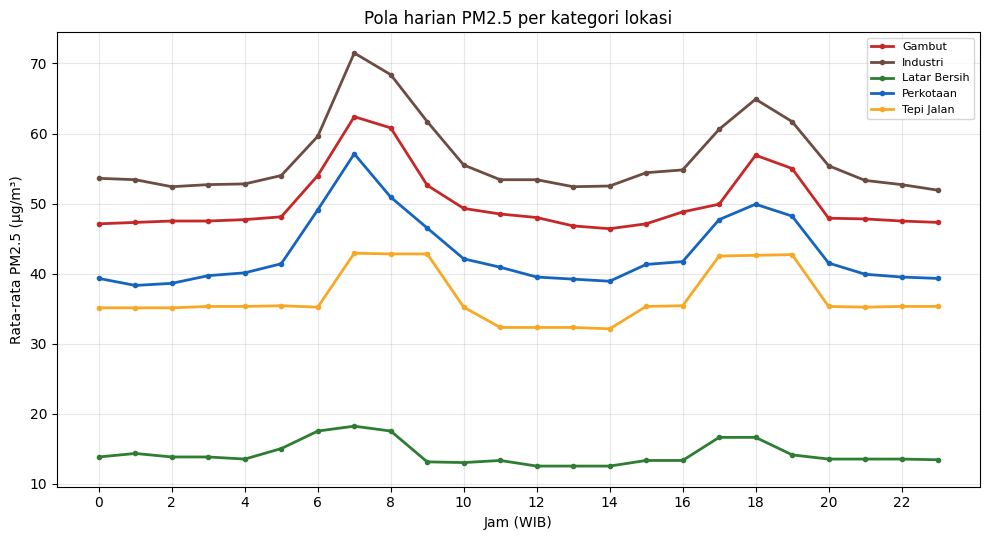

In [10]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for k, g in diurnal_kat.groupby("kategori_lokasi"):
    ax.plot(g["jam"], g["pm25"], marker="o", ms=3, lw=2, color=WARNA_KAT[k], label=k)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Jam (WIB)")
ax.set_ylabel("Rata-rata PM2.5 (µg/m³)")
ax.set_title("Pola harian PM2.5 per kategori lokasi")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "05_T2_pola_jam_kategori.png", dpi=150)
plt.show()

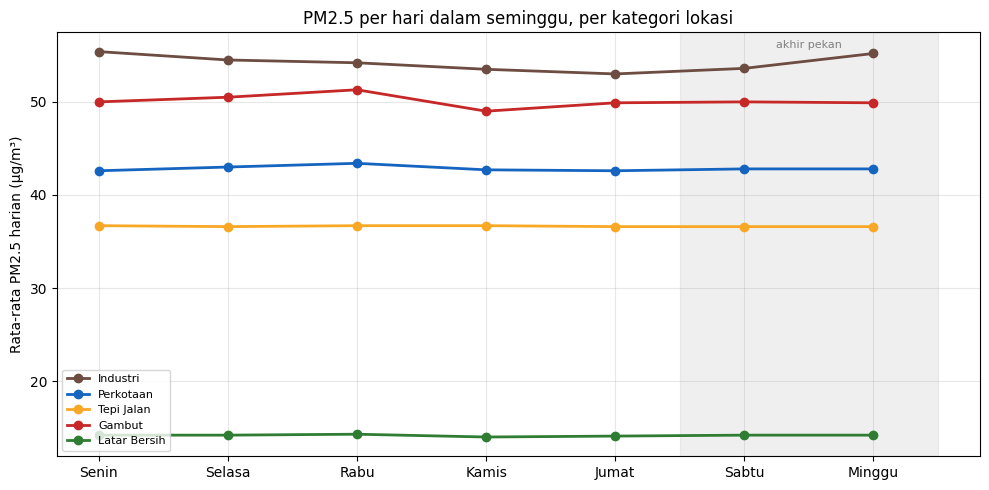

In [11]:
hk = hari_kat.loc[["Industri", "Perkotaan", "Tepi Jalan", "Gambut", "Latar Bersih"]]
fig, ax = plt.subplots(figsize=(10, 5))
for k, row in hk.iterrows():
    ax.plot(URUT_HARI, row.values, marker="o", lw=2, color=WARNA_KAT[k], label=k)
ax.axvspan(4.5, 6.5, color="grey", alpha=0.12)
ax.text(5.5, ax.get_ylim()[1] * 0.97, "akhir pekan", ha="center", fontsize=8, color="grey")
ax.set_ylabel("Rata-rata PM2.5 harian (µg/m³)")
ax.set_title("PM2.5 per hari dalam seminggu, per kategori lokasi")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "05_T2_pola_hari_kategori.png", dpi=150)
plt.show()

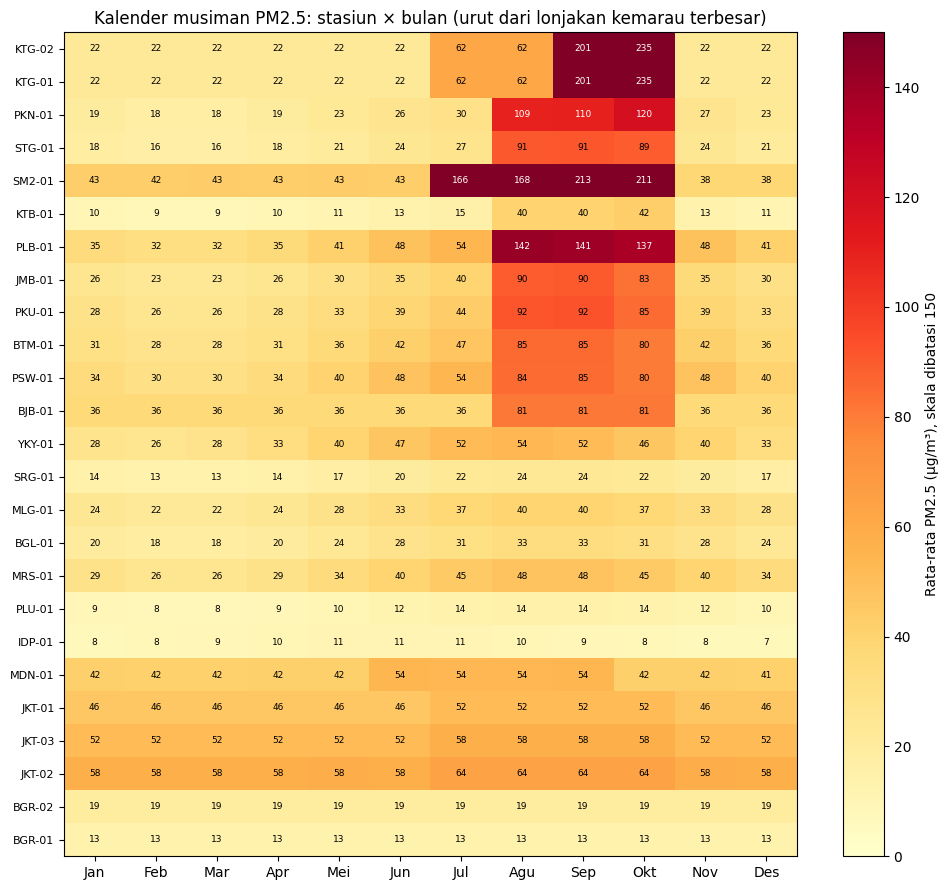

In [12]:
urut = musim.sort_values("rasio_kemarau_hujan", ascending=False)["stasiun"]
hm = bulan_st.loc[urut]
fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(hm.values, aspect="auto", cmap="YlOrRd", vmin=0, vmax=150)
ax.set_xticks(range(12))
ax.set_xticklabels(NAMA_BULAN)
ax.set_yticks(range(len(hm)))
ax.set_yticklabels(hm.index, fontsize=8)
for i in range(hm.shape[0]):
    for j in range(12):
        val = hm.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=6.5, color="white" if val > 100 else "black")
plt.colorbar(im, ax=ax, label="Rata-rata PM2.5 (µg/m³), skala dibatasi 150")
ax.set_title("Kalender musiman PM2.5: stasiun × bulan (urut dari lonjakan kemarau terbesar)")
plt.tight_layout()
plt.savefig(GAMBAR + "05_T2_heatmap_stasiun_bulan.png", dpi=150)
plt.show()

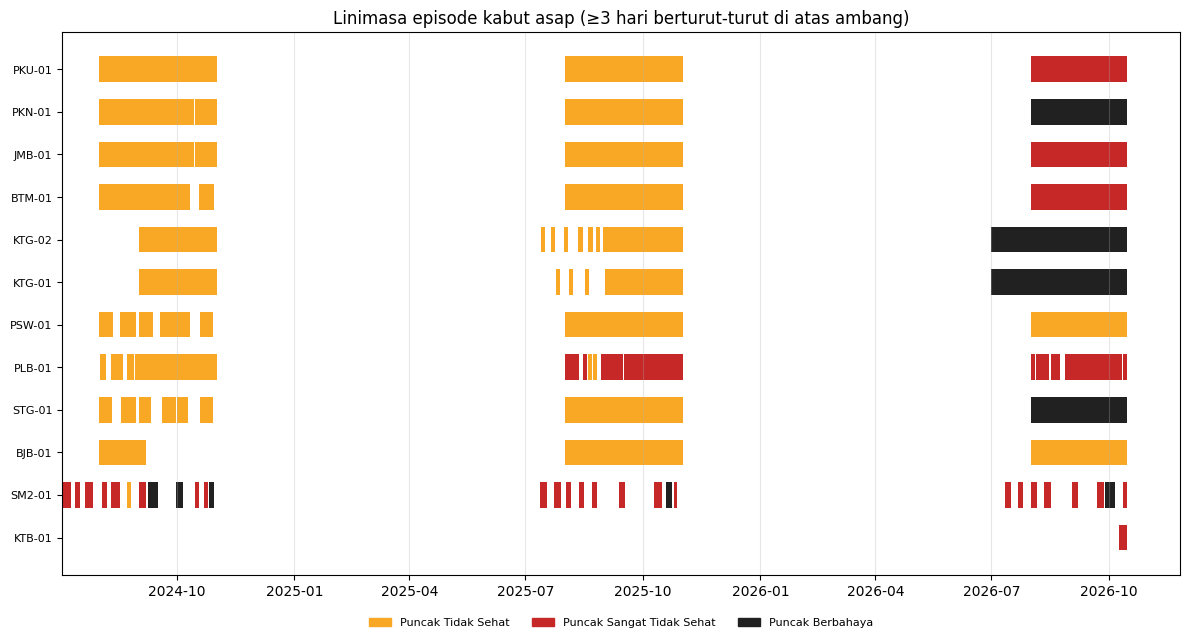

In [13]:
st_ep = ep.groupby("stasiun")["durasi_hari"].sum().sort_values().index
fig, ax = plt.subplots(figsize=(12, 6.5))
for i, st in enumerate(st_ep):
    for _, e in ep[ep["stasiun"] == st].iterrows():
        warna = "#212121" if e["pm25_puncak"] > 250.4 else "#c62828" if e["pm25_puncak"] > 150.4 else "#f9a825"
        ax.barh(i, (e["selesai"] - e["mulai"]).days + 1, left=e["mulai"], color=warna, height=0.6)
ax.set_yticks(range(len(st_ep)))
ax.set_yticklabels(st_ep, fontsize=8)
ax.set_title("Linimasa episode kabut asap (≥3 hari berturut-turut di atas ambang)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#f9a825", "#c62828", "#212121"]],
          labels=["Puncak Tidak Sehat", "Puncak Sangat Tidak Sehat", "Puncak Berbahaya"], fontsize=8,
          loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=3, frameon=False)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(GAMBAR + "05_T2_linimasa_episode_asap.png", dpi=150)
plt.show()

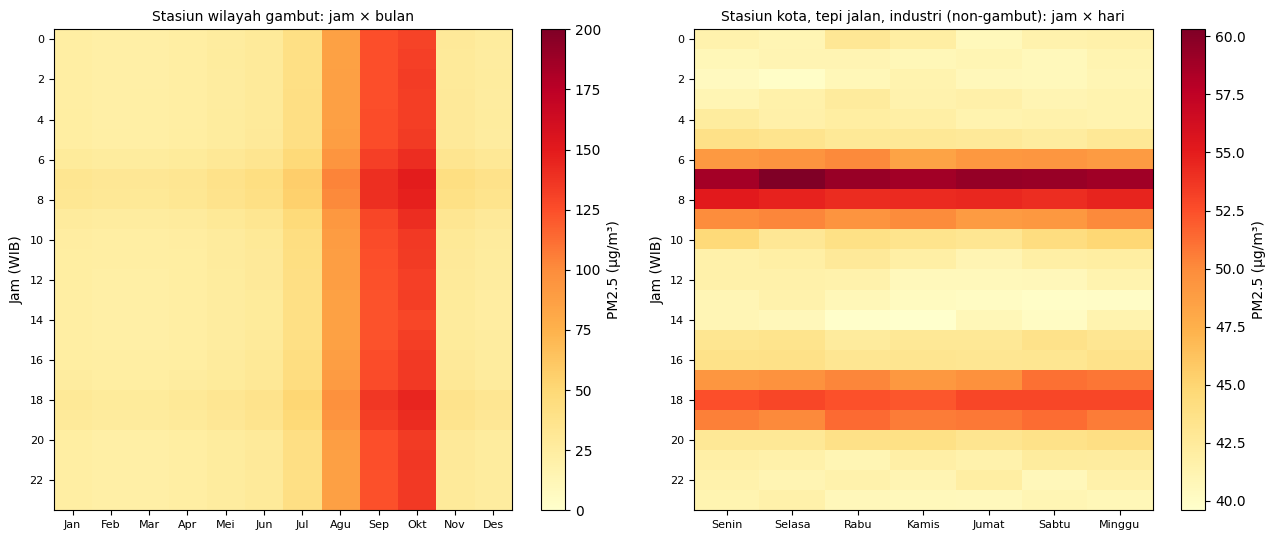

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (judul, data, vmax) in zip(axes, [("Stasiun wilayah gambut: jam × bulan", gambut_jb, 200),
                                          ("Stasiun kota, tepi jalan, industri (non-gambut): jam × hari", kota_hh, None)]):
    im = ax.imshow(data.values, aspect="auto", cmap="YlOrRd", vmin=0 if vmax else None, vmax=vmax)
    ax.set_xticks(range(data.shape[1]))
    ax.set_xticklabels(data.columns, fontsize=8)
    ax.set_yticks(range(0, 24, 2))
    ax.set_yticklabels(range(0, 24, 2), fontsize=8)
    ax.set_ylabel("Jam (WIB)")
    ax.set_title(judul, fontsize=10)
    plt.colorbar(im, ax=ax, label="PM2.5 (µg/m³)")
plt.tight_layout()
plt.savefig(GAMBAR + "05_T2_heatmap_waktu_rawan.png", dpi=150)
plt.show()

In [15]:
pd.set_option("display.width", 250)
print(kat_ring.to_string())
print(diurnal_kat.pivot(index="jam", columns="kategori_lokasi", values="pm25").to_string())
print(puncak.to_string())
print(pekan.to_string())
print(pekan_kat.to_string())
print(musim.to_string())
print(ring_ep_tahun.to_string())
print(ring_ep.to_string())
print(hari_serentak.to_string())
print(ep.sort_values("pm25_puncak", ascending=False).head(10).to_string())
print(kota_hh.loc[[6, 7, 8, 12, 17, 18, 19, 3]].to_string())

                 pm25_rata2  pm25_median  pm25_p95  koef_variasi  pct_hari_tidak_sehat  rasio_kemarau_hujan_rata2  selisih_hari_kerja_vs_akhir_pekan_pct  rasio_puncak_terendah_harian  jam_puncak
kategori_lokasi                                                                                                                                                                                   
Gambut                50.09        33.48    124.30          1.17                 25.31                       2.79                                    0.4                          1.34           7
Industri              54.21        45.29    145.08          0.66                 37.66                       1.83                                   -0.6                          1.38           7
Latar Bersih          14.17        12.95     24.45          0.59                  0.12                       1.54                                    0.0                          1.46           7
Perkotaan             42.